In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import pickle
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving student_data.csv to student_data.csv
Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardi

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

# Target column: G3 (final student grade)
TARGET_COLUMN = "G3"

# Remove rows where the final grade is missing
data = df.dropna(subset=[TARGET_COLUMN]).copy()

# Separate features and target
X = data.drop(columns=[TARGET_COLUMN])
y = data[TARGET_COLUMN].astype(float)

# Convert final grades into 3 classes
# Low: 0-9, Medium: 10-14, High: 15-20
y = pd.cut(
    y,
    bins=[-1, 9, 14, 20],
    labels=["Low", "Medium", "High"]
)

# Remove rows whose grades fall outside the defined bins
valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid]

# Encode target labels as numbers
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y.astype(str))

# Fill missing input values
for col in X.columns:
    if X[col].dtype == "object":
        mode = X[col].mode()
        X[col] = X[col].fillna(
            mode.iloc[0] if not mode.empty else "Unknown"
        )
    else:
        X[col] = X[col].fillna(X[col].median())

# Convert categorical features to numeric columns
X = pd.get_dummies(X, drop_first=False, dtype=int)
X = X.astype(float)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

num_classes = len(np.unique(y_train))

print("Dataset prepared successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X_train_scaled.shape[1])
print("Target classes:", label_encoder.classes_)
print("Training data shape:", X_train_scaled.shape)

Dataset prepared successfully!
Training samples: 316
Testing samples: 79
Input features: 58
Target classes: ['High' 'Low' 'Medium']
Training data shape: (316, 58)


In [6]:

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Model trained successfully!")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_.astype(str),
    zero_division=0
))

Model trained successfully!
Accuracy: 81.01 %

Classification Report:
              precision    recall  f1-score   support

        High       0.71      0.67      0.69        15
         Low       0.86      0.92      0.89        26
      Medium       0.81      0.79      0.80        38

    accuracy                           0.81        79
   macro avg       0.79      0.79      0.79        79
weighted avg       0.81      0.81      0.81        79



In [7]:

with open("student_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved using pickle!")

Model saved using pickle!


In [8]:

with open("student_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

predictions = loaded_model.predict(X_test_scaled[:5])

print("Predicted classes:")
print(label_encoder.inverse_transform(predictions))

print("\nActual classes:")
print(label_encoder.inverse_transform(y_test[:5]))

Predicted classes:
['Low' 'Low' 'Medium' 'Medium' 'Low']

Actual classes:
['Low' 'Low' 'Medium' 'Medium' 'Low']


In [9]:

joblib.dump(model, "student_model.joblib")

loaded_joblib_model = joblib.load("student_model.joblib")

joblib_predictions = loaded_joblib_model.predict(X_test_scaled[:5])

print("Joblib model loaded successfully!")
print("Predictions:", label_encoder.inverse_transform(joblib_predictions))

Joblib model loaded successfully!
Predictions: ['Low' 'Low' 'Medium' 'Medium' 'Low']


In [10]:

artifacts = {
    "model": model,
    "scaler": scaler,
    "feature_columns": X.columns.tolist(),
    "label_encoder": label_encoder
}

joblib.dump(artifacts, "student_deployment_bundle.joblib")

loaded_bundle = joblib.load("student_deployment_bundle.joblib")

print("Deployment bundle saved and loaded successfully!")
print("Saved feature count:", len(loaded_bundle["feature_columns"]))

Deployment bundle saved and loaded successfully!
Saved feature count: 58


In [11]:

import numpy as np

def step_activation(z):
    return 1 if z >= 0 else 0

def perceptron(inputs, weights, bias):
    z = np.dot(inputs, weights) + bias
    return step_activation(z)

# AND gate dataset
inputs = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

weights = np.array([1, 1])
bias = -1.5

for row in inputs:
    print(row, "->", perceptron(row, weights, bias))

[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1


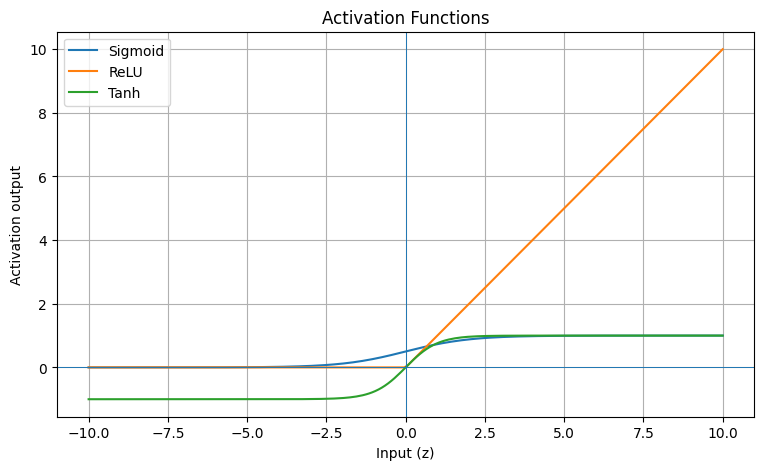

In [12]:

import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-10, 10, 200)

sigmoid = 1 / (1 + np.exp(-z))
relu = np.maximum(0, z)
tanh = np.tanh(z)

plt.figure(figsize=(9, 5))
plt.plot(z, sigmoid, label="Sigmoid")
plt.plot(z, relu, label="ReLU")
plt.plot(z, tanh, label="Tanh")
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.title("Activation Functions")
plt.xlabel("Input (z)")
plt.ylabel("Activation output")
plt.legend()
plt.grid(True)
plt.show()

In [13]:

import numpy as np

# One sample with two inputs
x = np.array([[0.5, 0.8]])

# Weights and biases for a small network
W1 = np.array([[0.2, 0.4],
               [0.3, 0.1]])
b1 = np.array([[0.1, 0.1]])

W2 = np.array([[0.5],
               [0.6]])
b2 = np.array([[0.2]])

# Hidden layer: ReLU
z1 = x @ W1 + b1
a1 = np.maximum(0, z1)

# Output layer: sigmoid
z2 = a1 @ W2 + b2
prediction = 1 / (1 + np.exp(-z2))

print("Hidden layer output:", a1)
print("Final prediction:", prediction)

Hidden layer output: [[0.44 0.38]]
Final prediction: [[0.65655963]]


In [14]:

import numpy as np

# Mean Squared Error (MSE)
actual = np.array([1.0, 0.0, 1.0])
predicted = np.array([0.8, 0.2, 0.6])

mse = np.mean((actual - predicted) ** 2)

# Binary Cross-Entropy
epsilon = 1e-7
p = np.clip(predicted, epsilon, 1 - epsilon)

binary_cross_entropy = -np.mean(
    actual * np.log(p) + (1 - actual) * np.log(1 - p)
)

print("Mean Squared Error:", mse)
print("Binary Cross-Entropy:", binary_cross_entropy)

Mean Squared Error: 0.08
Binary Cross-Entropy: 0.3190375754648034


In [15]:

import numpy as np
import matplotlib.pyplot as plt

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def train_neural_network(
    X, y, X_val, y_val,
    optimizer="adam",
    epochs=100,
    learning_rate=0.01,
    hidden_size=16,
    batch_size=32
):
    np.random.seed(42)

    n_samples, n_features = X.shape
    n_classes = len(np.unique(y))

    # One-hot encode the target
    Y = np.eye(n_classes)[y]
    Y_val = np.eye(n_classes)[y_val]

    # Initialize weights and biases
    W1 = np.random.randn(n_features, hidden_size) * np.sqrt(2 / n_features)
    b1 = np.zeros((1, hidden_size))

    W2 = np.random.randn(hidden_size, n_classes) * np.sqrt(2 / hidden_size)
    b2 = np.zeros((1, n_classes))

    params = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

    # Adam optimizer state
    m = {k: np.zeros_like(v) for k, v in params.items()}
    v = {k: np.zeros_like(val) for k, val in params.items()}
    beta1, beta2 = 0.9, 0.999
    epsilon = 1e-8
    step = 0

    history = {"loss": [], "val_loss": [], "accuracy": []}

    for epoch in range(epochs):
        indices = np.random.permutation(n_samples)

        for start in range(0, n_samples, batch_size):
            batch_indices = indices[start:start + batch_size]
            xb = X[batch_indices]
            yb = Y[batch_indices]
            batch_n = len(xb)

            # 1. Forward propagation
            z1 = xb @ W1 + b1
            a1 = np.maximum(0, z1)  # ReLU

            z2 = a1 @ W2 + b2
            probs = softmax(z2)

            # 2. Backpropagation
            dz2 = (probs - yb) / batch_n
            dW2 = a1.T @ dz2
            db2 = np.sum(dz2, axis=0, keepdims=True)

            da1 = dz2 @ W2.T
            dz1 = da1 * (z1 > 0)
            dW1 = xb.T @ dz1
            db1 = np.sum(dz1, axis=0, keepdims=True)

            grads = {
                "W1": dW1, "b1": db1,
                "W2": dW2, "b2": db2
            }

            # 3. Update parameters
            step += 1

            if optimizer.lower() == "sgd":
                for key in params:
                    params[key] -= learning_rate * grads[key]

            elif optimizer.lower() == "adam":
                for key in params:
                    m[key] = beta1 * m[key] + (1 - beta1) * grads[key]
                    v[key] = beta2 * v[key] + (1 - beta2) * grads[key] ** 2

                    m_hat = m[key] / (1 - beta1 ** step)
                    v_hat = v[key] / (1 - beta2 ** step)

                    params[key] -= (
                        learning_rate * m_hat /
                        (np.sqrt(v_hat) + epsilon)
                    )
            else:
                raise ValueError("Optimizer must be 'sgd' or 'adam'")

        # Evaluate after each epoch
        train_probs = softmax(
            np.maximum(0, X @ W1 + b1) @ W2 + b2
        )
        val_probs = softmax(
            np.maximum(0, X_val @ W1 + b1) @ W2 + b2
        )

        train_loss = -np.mean(
            np.sum(Y * np.log(np.clip(train_probs, 1e-12, 1)), axis=1)
        )
        val_loss = -np.mean(
            np.sum(Y_val * np.log(np.clip(val_probs, 1e-12, 1)), axis=1)
        )
        train_acc = np.mean(
            np.argmax(train_probs, axis=1) == y
        )

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["accuracy"].append(train_acc)

    return params, history


print("Neural network functions defined successfully!")

Neural network functions defined successfully!


In [16]:

# Train with SGD
sgd_params, sgd_history = train_neural_network(
    X_train_scaled, y_train,
    X_test_scaled, y_test,
    optimizer="sgd",
    epochs=100,
    learning_rate=0.01
)

# Train with Adam
adam_params, adam_history = train_neural_network(
    X_train_scaled, y_train,
    X_test_scaled, y_test,
    optimizer="adam",
    epochs=100,
    learning_rate=0.01
)

print("Both neural networks trained successfully!")
print("SGD final training loss:", round(sgd_history["loss"][-1], 4))
print("Adam final training loss:", round(adam_history["loss"][-1], 4))

Both neural networks trained successfully!
SGD final training loss: 0.2776
Adam final training loss: 0.0011


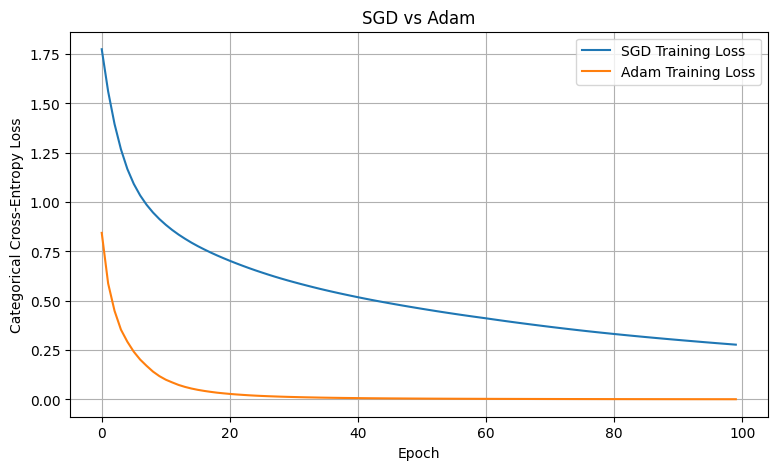

In [17]:

plt.figure(figsize=(9, 5))

plt.plot(sgd_history["loss"], label="SGD Training Loss")
plt.plot(adam_history["loss"], label="Adam Training Loss")

plt.title("SGD vs Adam")
plt.xlabel("Epoch")
plt.ylabel("Categorical Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:

def predict_neural_network(X, params):
    hidden = np.maximum(0, X @ params["W1"] + params["b1"])
    probabilities = softmax(hidden @ params["W2"] + params["b2"])
    return np.argmax(probabilities, axis=1)

sgd_predictions = predict_neural_network(X_test_scaled, sgd_params)
adam_predictions = predict_neural_network(X_test_scaled, adam_params)

print("SGD accuracy:",
      round(accuracy_score(y_test, sgd_predictions) * 100, 2), "%")

print("Adam accuracy:",
      round(accuracy_score(y_test, adam_predictions) * 100, 2), "%")

print("\nAdam Classification Report:")
print(classification_report(
    y_test,
    adam_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_.astype(str),
    zero_division=0
))

print("Adam Confusion Matrix:")
print(confusion_matrix(
    y_test, adam_predictions,
    labels=np.arange(len(label_encoder.classes_))
))

SGD accuracy: 72.15 %
Adam accuracy: 69.62 %

Adam Classification Report:
              precision    recall  f1-score   support

        High       0.56      0.60      0.58        15
         Low       0.78      0.81      0.79        26
      Medium       0.69      0.66      0.68        38

    accuracy                           0.70        79
   macro avg       0.68      0.69      0.68        79
weighted avg       0.70      0.70      0.70        79

Adam Confusion Matrix:
[[ 9  0  6]
 [ 0 21  5]
 [ 7  6 25]]


In [19]:

neural_network_bundle = {
    "parameters": adam_params,
    "feature_columns": X.columns.tolist(),
    "scaler": scaler,
    "label_encoder": label_encoder,
    "hidden_activation": "ReLU",
    "output_activation": "Softmax",
    "optimizer": "Adam"
}

joblib.dump(neural_network_bundle, "student_numpy_neural_network.joblib")

print("NumPy neural network saved successfully!")

NumPy neural network saved successfully!


In [20]:

loaded_nn = joblib.load("student_numpy_neural_network.joblib")

loaded_predictions = predict_neural_network(
    X_test_scaled,
    loaded_nn["parameters"]
)

print("Loaded neural network accuracy:",
      round(accuracy_score(y_test, loaded_predictions) * 100, 2), "%")

print("First 5 predicted classes:",
      label_encoder.inverse_transform(loaded_predictions[:5]))

print("First 5 actual classes:",
      label_encoder.inverse_transform(y_test[:5]))

Loaded neural network accuracy: 69.62 %
First 5 predicted classes: ['Low' 'Low' 'Medium' 'Medium' 'Medium']
First 5 actual classes: ['Low' 'Low' 'Medium' 'Medium' 'Low']


In [21]:

from google.colab import files

files.download("student_model.pkl")
files.download("student_model.joblib")
files.download("student_deployment_bundle.joblib")
files.download("student_numpy_neural_network.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>